<a href="https://colab.research.google.com/github/yashadhalage2005-cloud/Yash-Adhalage-Business-Analytics-/blob/main/Yash_business_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_excel("Amazon 2_Raw.xlsx", sheet_name="Walmart")
df

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit
0,CA-2013-138688,2013-06-13,2013-06-17,DarrinVanHuff@gmail.com,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714
1,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694
2,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656
3,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152
4,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825
...,...,...,...,...,...,...,...,...,...,...
3198,CA-2013-125794,2013-09-30,2013-10-04,MarisLaWare@gmail.com,"United States,Los Angeles,California",Accessories,Memorex Mini Travel Drive 64 GB USB 2.0 Flash ...,36.240,1,15.2208
3199,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,15.6332
3200,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Phones,Aastra 57i VoIP phone,258.576,2,19.3932
3201,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,13.3200


In [ ]:
print("Dataset Shape:", df.shape)

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe(include="all"))

Dataset Shape: (3203, 10)

Number of Rows: 3203
Number of Columns: 10

Column Names:
['Order ID', 'Order Date', 'Ship Date', 'EmailID', 'Geography', 'Category', 'Product Name', 'Sales', 'Quantity', 'Profit']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3203 entries, 0 to 3202
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order ID      3203 non-null   object        
 1   Order Date    3203 non-null   datetime64[ns]
 2   Ship Date     3203 non-null   datetime64[ns]
 3   EmailID       3203 non-null   object        
 4   Geography     3203 non-null   object        
 5   Category      3203 non-null   object        
 6   Product Name  3203 non-null   object        
 7   Sales         3203 non-null   float64       
 8   Quantity      3203 non-null   int64         
 9   Profit        3203 non-null   float64       
dtypes: datetime64[ns](2), float64(2), int64(1), object(5)
memo

In [ ]:
df.isnull().sum()

,0
Order ID,0
Order Date,0
Ship Date,0
EmailID,0
Geography,0
Category,0
Product Name,0
Sales,0
Quantity,0
Profit,0


In [ ]:
df.duplicated().sum()

np.int64(0)

Interpretation
The dataset contains e-commerce transaction information such as Order ID, Order Date, Ship Date, Geography, Category, Product Name, Sales, Quantity, and Profit. Dataset understanding helps identify the number of records, available variables, data types, and overall structure before performing analysis.


Missing value analysis helps identify incomplete information in the dataset. Missing values can affect the accuracy of calculations and visualizations. Therefore, they should be handled before performing business analysis.

Data preprocessing improves data quality before analysis. Duplicate records are removed, while missing numerical values are replaced with the median to reduce the effect of extreme values. This makes the dataset more suitable for accurate analysis.

In [ ]:
print(df.dtypes)

Order ID                object
Order Date      datetime64[ns]
Ship Date       datetime64[ns]
EmailID                 object
Geography               object
Category                object
Product Name            object
Sales                  float64
Quantity                 int64
Profit                 float64
dtype: object


In [ ]:
df[["Country", "City", "State"]] = df["Geography"].str.split(",", expand=True)
df.head()

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit,Country,City,State
0,CA-2013-138688,2013-06-13,2013-06-17,DarrinVanHuff@gmail.com,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714,United States,Los Angeles,California
1,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694,United States,Los Angeles,California
2,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656,United States,Los Angeles,California
3,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152,United States,Los Angeles,California
4,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825,United States,Los Angeles,California


In [ ]:
print(df[["Geography", "Country", "City", "State"]].
head())

                              Geography        Country         City  \
0  United States,Los Angeles,California  United States  Los Angeles   
1  United States,Los Angeles,California  United States  Los Angeles   
2  United States,Los Angeles,California  United States  Los Angeles   
3  United States,Los Angeles,California  United States  Los Angeles   
4  United States,Los Angeles,California  United States  Los Angeles   

        State  
0  California  
1  California  
2  California  
3  California  
4  California  


The Geography column is divided into separate Country, City, and State columns. This transformation makes geographical analysis easier and allows comparison of sales performance across different regions.

In [ ]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()
df["Day"] = df["Order Date"].dt.day
df

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit,Country,City,State,Year,Month,Month Name,Day
0,CA-2013-138688,2013-06-13,2013-06-17,DarrinVanHuff@gmail.com,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714,United States,Los Angeles,California,2013,6,June,13
1,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694,United States,Los Angeles,California,2011,6,June,9
2,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656,United States,Los Angeles,California,2011,6,June,9
3,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152,United States,Los Angeles,California,2011,6,June,9
4,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825,United States,Los Angeles,California,2011,6,June,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3198,CA-2013-125794,2013-09-30,2013-10-04,MarisLaWare@gmail.com,"United States,Los Angeles,California",Accessories,Memorex Mini Travel Drive 64 GB USB 2.0 Flash ...,36.240,1,15.2208,United States,Los Angeles,California,2013,9,September,30
3199,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,15.6332,United States,Costa Mesa,California,2014,2,February,27
3200,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Phones,Aastra 57i VoIP phone,258.576,2,19.3932,United States,Costa Mesa,California,2014,2,February,27
3201,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,13.3200,United States,Costa Mesa,California,2014,2,February,27


New date features such as Year and Month are created to analyze sales patterns over time. This helps identify seasonal trends and periods with higher or lower sales.

In [ ]:
df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

df[["Order Date", "Ship Date", "Shipping Days"]].head()

,Order Date,Ship Date,Shipping Days
0,2013-06-13,2013-06-17,4
1,2011-06-09,2011-06-14,5
2,2011-06-09,2011-06-14,5
3,2011-06-09,2011-06-14,5
4,2011-06-09,2011-06-14,5


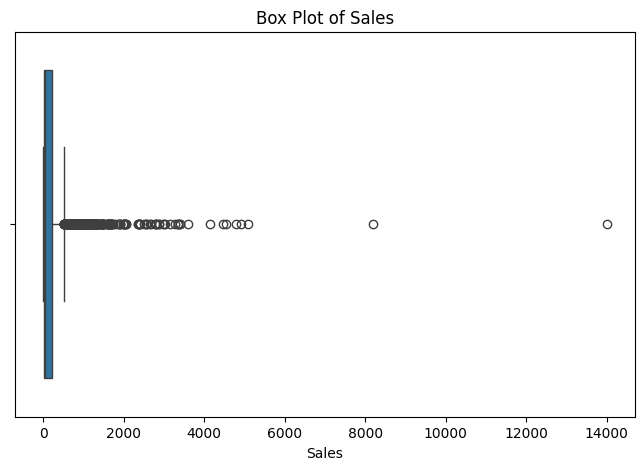

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Sales"])

plt.title("Box Plot of Sales")
plt.show()

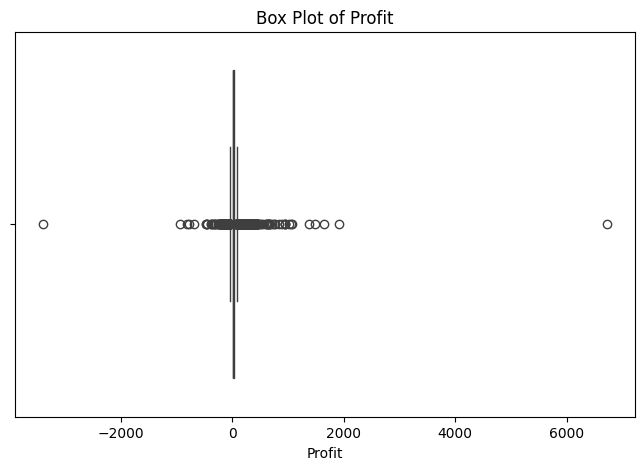

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Profit"])

plt.title("Box Plot of Profit")
plt.show()

In [ ]:
Q1 = df["Sales"].quantile(0.25)
Q3 = df["Sales"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Sales"] < lower_limit) |
    (df["Sales"] > upper_limit)
]

print("Number of Sales Outliers:", outliers.shape[0])

Number of Sales Outliers: 368


In [ ]:
state_sales = (
    df.groupby("State")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(state_sales)

State
California    457687.6315
Washington    138641.2700
Arizona        35282.0010
Colorado       32108.1180
Oregon         17431.1500
Nevada         16729.1020
Utah           11220.0560
Montana         5589.3520
New Mexico      4783.5220
Idaho           4382.4860
Wyoming         1603.1360
Name: Sales, dtype: float64


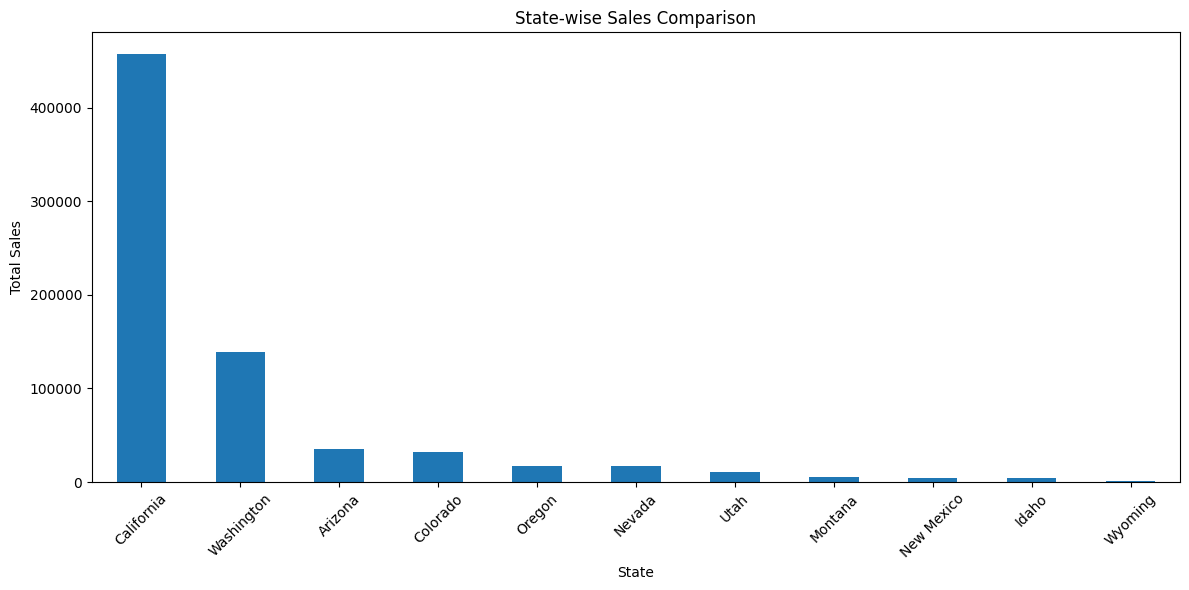

In [ ]:
plt.figure(figsize=(12, 6))

state_sales.plot(kind="bar")

plt.title("State-wise Sales Comparison")
plt.xlabel("State")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

Category
Chairs         101781.3280
Phones          98684.3520
Tables          84754.5620
Storage         70532.8520
Accessories     61114.1160
Binders         55961.1130
Copiers         49749.2420
Machines        42444.1220
Bookcases       36004.1235
Appliances      30236.3360
Furnishings     30072.7300
Paper           26663.7180
Supplies        18127.1220
Art              9212.0660
Labels           5078.7260
Envelopes        4118.1000
Fasteners         923.2160
Name: Sales, dtype: float64


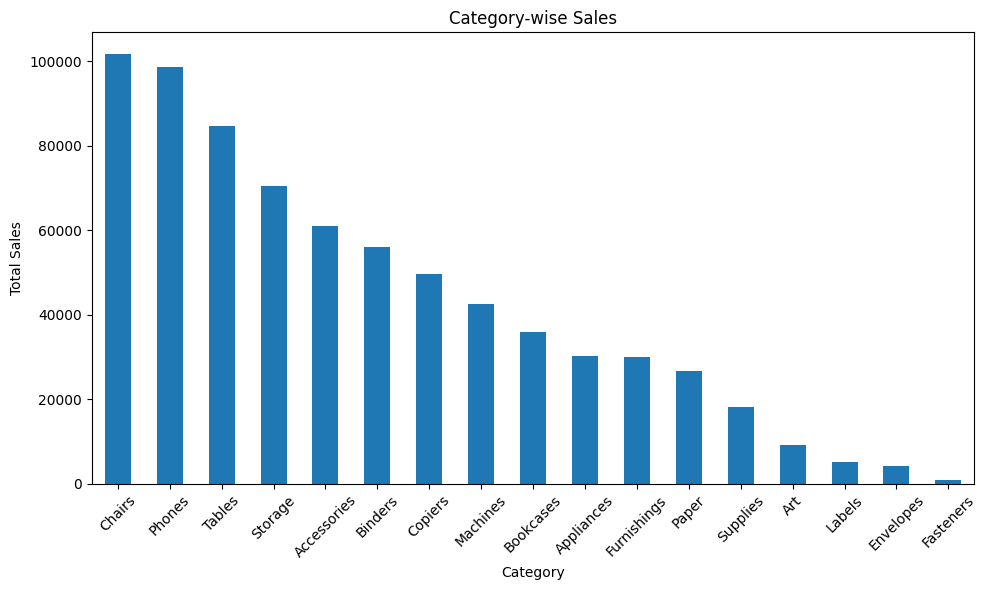

In [ ]:
plt.figure(figsize=(10, 6))

category_sales.plot(kind="bar")

plt.title("Category-wise Sales")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
category_profit = (
    df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print(category_profit)

Category
Copiers        19327.2351
Accessories    16484.5983
Binders        16096.8016
Paper          12119.2364
Phones          9110.7426
Storage         8645.3222
Appliances      8261.2699
Furnishings     7641.2704
Chairs          4027.5843
Art             2374.0970
Labels          2303.1223
Envelopes       1908.7624
Tables          1482.6073
Supplies         626.0465
Fasteners        275.1907
Machines        -618.9264
Bookcases      -1646.5117
Name: Profit, dtype: float64


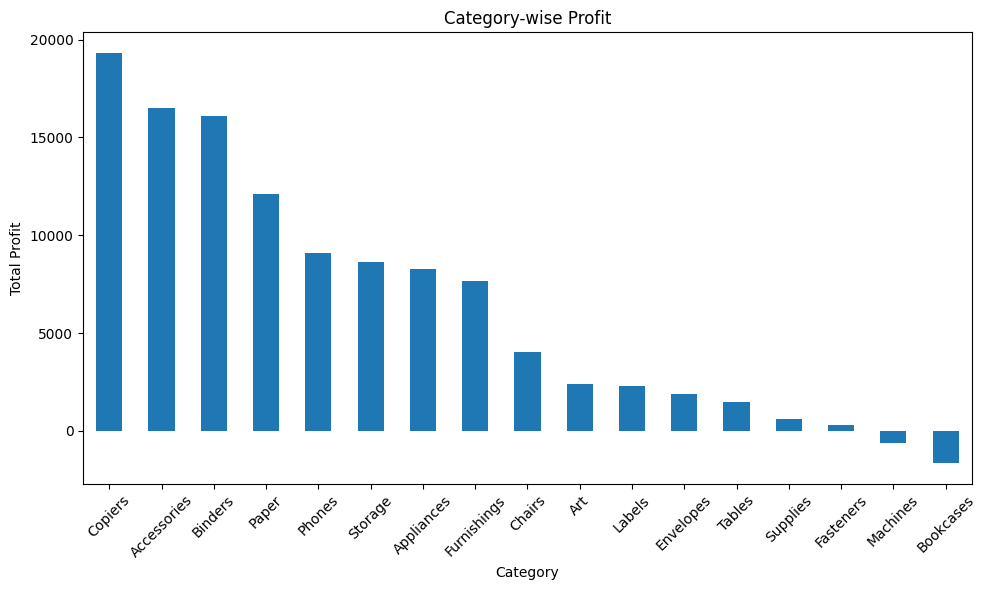

In [ ]:
plt.figure(figsize=(10, 6))

category_profit.plot(kind="bar")

plt.title("Category-wise Profit")
plt.xlabel("Category")
plt.ylabel("Total Profit")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          13999.960
High Speed Automatic Electric Letter Opener                                    13100.240
Global Troy Executive Leather Low-Back Tilter                                  10019.600
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     8134.336
GuestStacker Chair with Chrome Finish Legs                                      8030.016
Okidata MB760 Printer                                                           7834.400
Bretford Rectangular Conference Table Tops                                      7710.665
LogitechÂ P710e Mobile Speakerphone                                             7467.210
Canon PC1060 Personal Laser Copier                                              6719.904
Hewlett Packard LaserJet 3310 Copier                                            6239.896
Name: Sales, dtype: float64


/tmp/ipykernel_614/1359978893.py:11: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


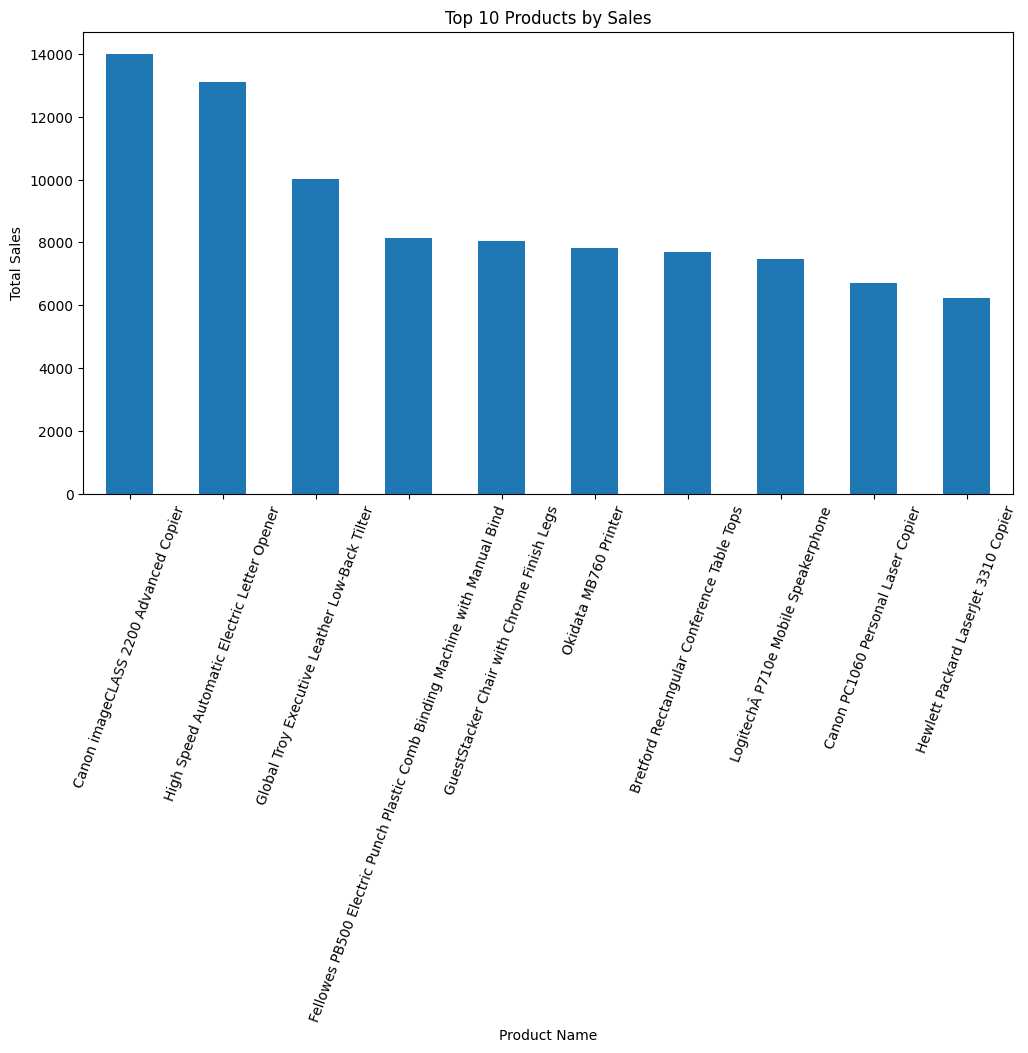

In [ ]:
plt.figure(figsize=(12, 6))

top_products.plot(kind="bar")

plt.title("Top 10 Products by Sales")
plt.xlabel("Product Name")
plt.ylabel("Total Sales")

plt.xticks(rotation=70)

plt.tight_layout()
plt.show()

In [ ]:
pareto = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

pareto["Cumulative Sales"] = pareto["Sales"].cumsum()

pareto["Cumulative Percentage"] = (
    pareto["Cumulative Sales"] /
    pareto["Sales"].sum()
) * 100

pareto.head()

,Product Name,Sales,Cumulative Sales,Cumulative Percentage
0,Canon imageCLASS 2200 Advanced Copier,13999.960,13999.960,1.929810
1,High Speed Automatic Electric Letter Opener,13100.240,27100.200,3.735600
2,Global Troy Executive Leather Low-Back Tilter,10019.600,37119.800,5.116741
3,Fellowes PB500 Electric Punch Plastic Comb Bin...,8134.336,45254.136,6.238011
4,GuestStacker Chair with Chrome Finish Legs,8030.016,53284.152,7.344900


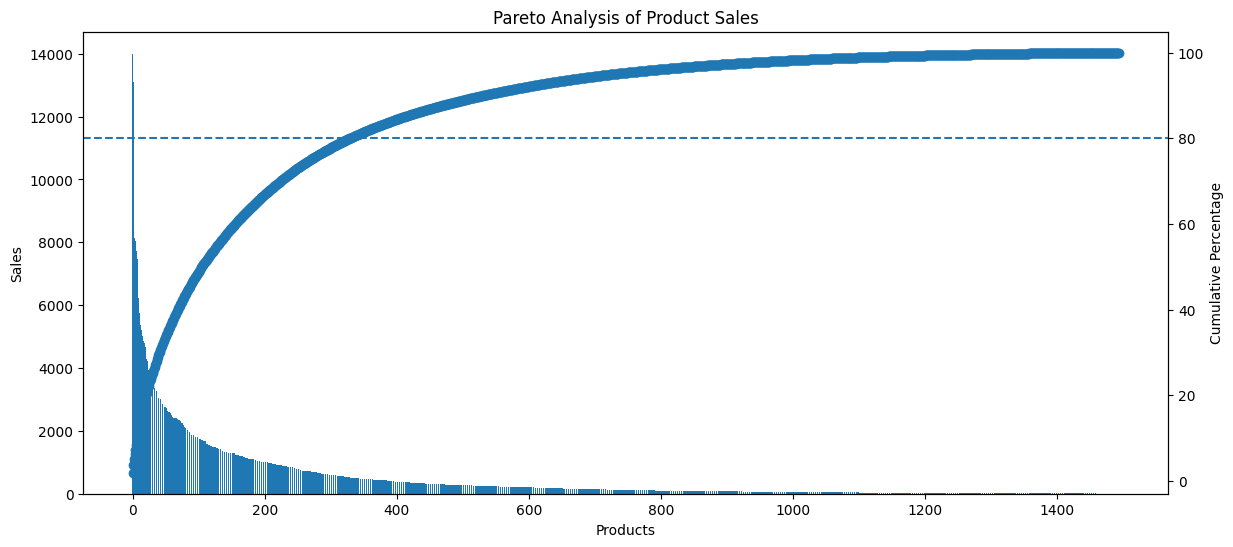

In [ ]:
plt.figure(figsize=(14, 6))

plt.bar(
    range(len(pareto)),
    pareto["Sales"]
)

plt.title("Pareto Analysis of Product Sales")
plt.xlabel("Products")
plt.ylabel("Sales")

plt.twinx()

plt.plot(
    range(len(pareto)),
    pareto["Cumulative Percentage"],
    marker="o"
)

plt.ylabel("Cumulative Percentage")

plt.axhline(80, linestyle="--")

plt.show()

In [ ]:
top_80_products = pareto[
    pareto["Cumulative Percentage"] <= 80
]

print("Number of Products Contributing to 80% Sales:")
print(top_80_products.shape[0])

top_80_products.head(10)

Number of Products Contributing to 80% Sales:
329


,Product Name,Sales,Cumulative Sales,Cumulative Percentage
0,Canon imageCLASS 2200 Advanced Copier,13999.960,13999.960,1.929810
1,High Speed Automatic Electric Letter Opener,13100.240,27100.200,3.735600
2,Global Troy Executive Leather Low-Back Tilter,10019.600,37119.800,5.116741
3,Fellowes PB500 Electric Punch Plastic Comb Bin...,8134.336,45254.136,6.238011
4,GuestStacker Chair with Chrome Finish Legs,8030.016,53284.152,7.344900
5,Okidata MB760 Printer,7834.400,61118.552,8.424825
6,Bretford Rectangular Conference Table Tops,7710.665,68829.217,9.487694
7,LogitechÂ P710e Mobile Speakerphone,7467.210,76296.427,10.517004
8,Canon PC1060 Personal Laser Copier,6719.904,83016.331,11.443302
9,Hewlett Packard LaserJet 3310 Copier,6239.896,89256.227,12.303434


In [ ]:
abc = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

abc["Cumulative Sales"] = abc["Sales"].cumsum()

abc["Cumulative Percentage"] = (
    abc["Cumulative Sales"] /
    abc["Sales"].sum()
) * 100
abc

,Product Name,Sales,Cumulative Sales,Cumulative Percentage
0,Canon imageCLASS 2200 Advanced Copier,13999.960,13999.9600,1.929810
1,High Speed Automatic Electric Letter Opener,13100.240,27100.2000,3.735600
2,Global Troy Executive Leather Low-Back Tilter,10019.600,37119.8000,5.116741
3,Fellowes PB500 Electric Punch Plastic Comb Bin...,8134.336,45254.1360,6.238011
4,GuestStacker Chair with Chrome Finish Legs,8030.016,53284.1520,7.344900
...,...,...,...,...
1489,Avery 511,3.080,725448.0855,99.998658
1490,Bagged Rubber Bands,3.024,725451.1095,99.999074
1491,"Acco Banker's Clasps, 5 3/4""-Long",2.880,725453.9895,99.999471
1492,Wilson Jones DublLock D-Ring Binders,2.025,725456.0145,99.999751


In [ ]:
def abc_category(value):

    if value <= 80:
        return "A"

    elif value <= 95:
        return "B"

    else:
        return "C"


abc["ABC Category"] = abc[
    "Cumulative Percentage"
].apply(abc_category)

abc.head()

,Product Name,Sales,Cumulative Sales,Cumulative Percentage,ABC Category
0,Canon imageCLASS 2200 Advanced Copier,13999.960,13999.960,1.929810,A
1,High Speed Automatic Electric Letter Opener,13100.240,27100.200,3.735600,A
2,Global Troy Executive Leather Low-Back Tilter,10019.600,37119.800,5.116741,A
3,Fellowes PB500 Electric Punch Plastic Comb Bin...,8134.336,45254.136,6.238011,A
4,GuestStacker Chair with Chrome Finish Legs,8030.016,53284.152,7.344900,A


In [ ]:
abc_summary = (
    abc.groupby("ABC Category")
    .agg(
        Number_of_Products=("Product Name", "count"),
        Total_Sales=("Sales", "sum")
    )
)

print(abc_summary)

              Number_of_Products  Total_Sales
ABC Category                                 
A                            329  580206.9965
B                            399  108942.5210
C                            766   36308.3070
